# 01 – Exploration des feux de forêt

**Question du projet :** *« Quelle est la probabilité qu'un feu démarre dans une commune donnée, un jour donné ? »*

**Objectif de ce notebook :** découvrir les données de feux (BDIFF), comprendre leur structure, et choisir le département sur lequel on construira le modèle.

**Source :** [BDIFF](https://bdiff.agriculture.gouv.fr) – Base de Données sur les Incendies de Forêts en France. Export CSV de tous les feux de forêt de France, 2016 → 2025.

## Étape 1 – Charger le CSV

Le fichier a quelques particularités qu'il faut connaître avant de le lire :
- séparateur `;` (format français) ;
- les **3 premières lignes** sont du texte (les critères de l'export) → `skiprows=3` ;
- les codes département et INSEE doivent rester du **texte** : sinon `"06"` devient le nombre `6` et `"06088"` devient `6088`, et les jointures futures échouent sans message d'erreur → `dtype=` ;
- les dates sont du texte (`"2016-01-02 11:56:00"`) → `pd.to_datetime` les transforme en vraies dates, dont on peut extraire l'année ou le mois avec `.dt`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(
    "../data/raw/Incendies.csv",
    sep=";",
    skiprows=3,
    encoding="utf-8",
    dtype={"Département": str, "Code INSEE": str},
)

df["date"] = pd.to_datetime(df["Date de première alerte"])
df["annee"] = df["date"].dt.year
df["mois"] = df["date"].dt.month

print(df.shape)
df.head()

(27444, 27)


,Année,Numéro,Département,Code INSEE,Nom de la commune,Date de première alerte,Surface parcourue (m2),Surface forêt (m2),Surface maquis garrigues (m2),Autres surfaces naturelles hors forêt (m2),...,Type de peuplement,Nature,Décès ou bâtiments touchés,Nombre de décès,Nombre de bâtiments totalement détruits,Nombre de bâtiments partiellement détruits,Précision de la donnée,date,annee,mois
0,2016,4608,66,66225,Villelongue-dels-Monts,2016-01-01 15:37:00,10,10.0,NaN,NaN,...,3.0,Involontaire (particulier),NaN,NaN,NaN,NaN,NaN,2016-01-01 15:37:00,2016,1
1,2016,6821,66,66026,Brouilla,2016-01-02 11:56:00,10000,10000.0,0.0,NaN,...,2.0,Involontaire (travaux),NaN,NaN,NaN,NaN,NaN,2016-01-02 11:56:00,2016,1
2,2016,12337,66,66106,Maureillas-las-Illas,2016-01-04 13:30:00,20,NaN,20.0,NaN,...,4.0,Malveillance,NaN,NaN,NaN,NaN,NaN,2016-01-04 13:30:00,2016,1
3,2016,6,974,97424,Cilaos,2016-01-05 16:05:00,800,0.0,NaN,800.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2016-01-05 16:05:00,2016,1
4,2016,7868,06,06086,Moulinet,2016-01-07 18:36:00,800,NaN,800.0,NaN,...,1.0,Involontaire (particulier),NaN,NaN,NaN,NaN,NaN,2016-01-07 18:36:00,2016,1


**27 444 feux** et 24 colonnes. Une ligne = un feu.

> Rappel : une cellule n'affiche automatiquement que le résultat de sa **dernière ligne**. D'où une cellule par question dans la suite.

## Étape 2 – Où brûle-t-on le plus ?

In [2]:
print(df["Département"].nunique(), "départements")
df["Département"].value_counts().head(15)

96 départements


Département
13     2699
11     1874
2B     1769
2A     1685
34     1557
33     1380
66     1164
83     1136
06      844
30      797
40      763
07      697
04      594
974     582
38      556
Name: count, dtype: int64

`value_counts()` compte les occurrences et trie par ordre décroissant ; `head(15)` n'affiche que les 15 premiers.

**96 départements** sur 101. Les 5 absents sont logiques : Paris et la petite couronne (75, 92, 93, 94), quasiment sans forêt, et la Guyane (973), non couverte par la BDIFF. Le **Sud-Est** domine nettement : Bouches-du-Rhône, Aude, Corse, Hérault…

## Étape 3 – Quand ?

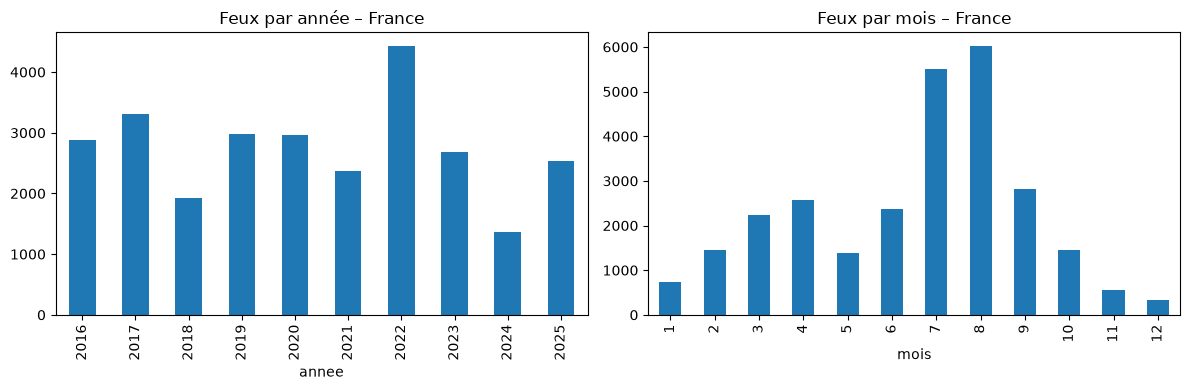

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df["annee"].value_counts().sort_index().plot(kind="bar", ax=axes[0], title="Feux par année – France")
df["mois"].value_counts().sort_index().plot(kind="bar", ax=axes[1], title="Feux par mois – France")
plt.tight_layout()
plt.show()

- **Par année :** de 1 367 feux (2024) à 4 433 (2022, année de sécheresse record). Ces écarts énormes d'une année à l'autre montrent que la **météo** sera déterminante.
- **Par mois :** un pic l'été, et un second plus petit en fin d'hiver / début de printemps (végétation sèche avant la repousse, brûlages).

## Étape 4 – Pourquoi ? (la cause)

In [4]:
df["Nature"].value_counts(dropna=False)

Nature
NaN                           14350
Malveillance                   4196
Involontaire (particulier)     3303
Involontaire (travaux)         2297
Accidentelle                   2003
Naturelle                      1295
Name: count, dtype: int64

`dropna=False` affiche aussi les valeurs manquantes (`NaN`). **52 % des causes sont inconnues** : cette colonne est inutilisable comme feature. Parmi les causes connues, la malveillance et les imprudences dominent : **l'activité humaine** compte, ce qui justifiera des features comme le week-end.

## Étape 5 – Choisir un département

Travailler sur toute la France ferait 35 000 communes × 3 650 jours = **128 millions de lignes**, et autant d'appels à l'API météo : trop pour un premier projet sur un portable. On choisit un département avec :
- **beaucoup de feux** (pour que le modèle ait des exemples) ;
- **peu de communes** (pour garder des volumes gérables).

👉 **Bouches-du-Rhône (13)** : 1ᵉʳ département de France en nombre de feux, pour seulement 119 communes.

In [5]:
df13 = df[df["Département"] == "13"].copy()
print(df13.shape)

(2699, 27)


`.copy()` crée un tableau **indépendant** de `df` : sans ça, pandas avertit (`SettingWithCopyWarning`) dès qu'on ajoute une colonne.

## Étape 6 – Les feux des Bouches-du-Rhône

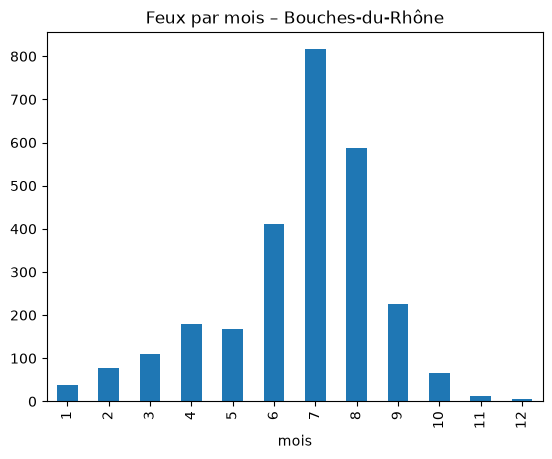

In [6]:
df13["mois"].value_counts().sort_index().plot(kind="bar", title="Feux par mois – Bouches-du-Rhône")
plt.show()

Un énorme pic en **juillet** (≈ 30 % des feux de l'année) et un petit pic en **avril**.

In [7]:
df13["Nom de la commune"].value_counts().head(10)

Nom de la commune
Martigues               224
Aix-en-Provence         162
Istres                  136
Marseille               120
Les Pennes-Mirabeau      87
Miramas                  84
Aubagne                  75
Fos-sur-Mer              70
Septèmes-les-Vallons     69
Port-de-Bouc             63
Name: count, dtype: int64

**Martigues, Aix-en-Provence, Istres, Marseille** en tête : de grandes communes, avec des massifs proches de zones habitées. L'**historique de feux de la commune** sera une feature précieuse.

In [8]:
df13["Surface parcourue (m2)"].describe()

count    2.699000e+03
mean     4.028654e+04
std      6.716207e+05
min      1.000000e+00
25%      2.000000e+01
50%      2.000000e+02
75%      1.000000e+03
max      2.663000e+07
Name: Surface parcourue (m2), dtype: float64

La **médiane** (50 %) est de 200 m² – un petit jardin – alors que la **moyenne** est de 40 000 m², tirée vers le haut par quelques méga-feux (jusqu'à 2 663 ha). La plupart des départs restent minuscules : on a raison de prédire le **départ** de feu, pas sa taille.

## Étape 7 – Un feu par commune et par jour ?

Notre cible sera *« au moins un feu dans la commune ce jour-là »*. Plusieurs feux le même jour dans la même commune ne compteront donc qu'une fois.

In [9]:
df13["jour"] = df13["date"].dt.normalize()   # garde la date, met l'heure à 00:00
print(len(df13), "feux")
print(df13.groupby(["Code INSEE", "jour"]).ngroups, "couples commune × jour avec au moins un feu")

2699 feux
2480 couples commune × jour avec au moins un feu


**2 699 feux → 2 480 couples commune × jour.** C'est ce second chiffre qui sera le nombre de « 1 » de notre cible.

## Récap

- 27 444 feux en France (2016-2025), très saisonniers, très variables d'une année à l'autre → la météo comptera.
- Cause inconnue dans 52 % des cas → pas utilisable.
- **Département retenu : Bouches-du-Rhône (13)** – 2 699 feux, 119 communes, 2 480 couples commune × jour avec feu.

**Prochaine étape (02) :** construire la table *une ligne = une commune × un jour* avec la cible 0/1.